# Early, Correct, and for the Right Reason? Reliability of Shapelet-Based Early Time-Series Classification under Distribution Shift

**A reliability pilot for shapelet-based early classification — Ashhar Hussain, November 2026**

Early classifiers are usually scored by accuracy and earliness on a clean benchmark split, often combined into one
harmonic mean (HM). Shapelet-based early classifiers are attractive because the matched subsequence doubles as the
explanation. This notebook asks three questions that a clean benchmark score cannot answer:

1. **Shortcut test (controlled):** when an *early* spurious pattern is correlated with the label at training time,
   does an earliness-rewarding shapelet selection prefer it over the *late* true evidence, and does HM notice?
2. **Shift test (real data):** how do accuracy, earliness and the triggering shapelets change under realistic
   acquisition shifts (noise, gain, baseline wander, time scaling, onset misalignment)?
3. **Diversity as corroboration:** does requiring two *different* shapelets to agree (a diversity-constrained double
   cover) buy robustness, and at what cost in earliness?

**Honest scope.** The classifier is a simplified, from-scratch EDSC-style method (random candidate sampling,
learned distance thresholds, greedy covering, first-match decisions). It is *not* a re-implementation of any
published algorithm — IEDSC, for example, also uses a trend-aware similarity and start-position pruning, which are
not implemented here. "SynECG" is a **simulated** single-beat ECG benchmark with a planted artefact, used because
ground truth about where the evidence lies is known exactly; it says nothing about clinical performance.
No hyperparameter was tuned on test data. Runs on a CPU in about a minute.

## 0. Setup

In [1]:
import sys, subprocess, importlib, time, json, os, math, warnings, zlib
try:
    import aeon  # used only to load the UCR datasets (GunPoint and ItalyPowerDemand ship with aeon)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "aeon"], check=True)
    import aeon
import numpy as np, pandas as pd, scipy, matplotlib
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import lfilter
from scipy.stats import binomtest
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220, "display.max_columns", 30)
OUT = "secr_outputs"; os.makedirs(OUT, exist_ok=True)
T_START = time.time()
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| aeon", aeon.__version__)

python 3.13.18 | numpy 2.3.5 | scipy 1.17.1 | pandas 3.0.5 | matplotlib 3.11.2 | aeon 1.6.0


## 1. Method: data, shifts, an EDSC-style shapelet early classifier, metrics

* **Candidates** are sampled at random from the training series (lengths 10/20/30% of the series).
* **Threshold:** each candidate gets the distance threshold that maximises the F-measure of matching its own class
  on the training set, with training precision ≥ 0.8.
* **Utility** = F-measure of precision and *earliness-weighted recall* $\frac{1}{N_c}\sum (1 - w\,e_x)$, where
  $e_x$ is the fraction of the series seen when the shapelet first matches. $w=0$ ignores earliness, $w=1$ rewards it.
* **Selection:** greedy covering by utility. *Diverse* selection skips a candidate that lies within the matching
  radius of an already-selected shapelet of the same class (redundant pattern).
* **Decision rules:** *first-match* (classify when any shapelet first matches) or *corroborated* (classify when two
  different shapelets of the same class have matched at non-overlapping positions).
* **Metrics:** accuracy, earliness (mean fraction observed at decision), HM of accuracy and (1 − earliness),
  fallback rate (no decision before the end), **shortcut rate** and **faithfulness** (SynECG: did the deciding
  evidence lie on the planted artefact or on the true T wave?), and **silent explanation change** (series that stay
  correctly classified under shift but are now explained by a different shapelet).
* **Statistics:** 5 seeds; hierarchical bootstrap 95% CIs (seeds, then series) for paired accuracy changes; exact
  McNemar tests per seed with Holm correction across the shift conditions of each method.

In [2]:
CFG = {
    "seeds": [0, 1, 2, 3, 4],
    "len_fracs": (0.10, 0.20, 0.30),  # candidate lengths as fractions of series length
    "n_cand_per_len": 240,            # random candidates per length, balanced over classes
    "p_min": 0.80,                    # minimum training precision of a usable shapelet
    "k_max": 60,                      # maximum shapelets kept by one model
    "n_boot": 2000,                   # bootstrap resamples for confidence intervals
    "alpha": 0.05,
}

# -----------------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------------
def to_codes(y):
    """Map arbitrary labels to 0..C-1 (sorted order)."""
    classes = np.unique(y)
    lut = {c: i for i, c in enumerate(classes)}
    return np.array([lut[c] for c in y], dtype=int), classes


def load_ucr(name):
    """UCR dataset with its default train/test split, through aeon.
    GunPoint and ItalyPowerDemand ship inside aeon (offline); other names are
    downloaded from timeseriesclassification.com (needs internet, e.g. Colab)."""
    from aeon.datasets import load_classification
    Xtr, ytr = load_classification(name, split="train")
    Xte, yte = load_classification(name, split="test")
    Xtr = np.asarray(Xtr, dtype=float)[:, 0, :]
    Xte = np.asarray(Xte, dtype=float)[:, 0, :]
    ytr, classes = to_codes(ytr)
    lut = {c: i for i, c in enumerate(classes)}
    yte = np.array([lut[c] for c in yte], dtype=int)
    return Xtr, ytr, Xte, yte


# Simulated single-beat ECG (static Gaussian-wave model in the spirit of ECGSYN).
# Each wave: (centre as fraction of the window, width as fraction, amplitude).
WAVES = {
    "P": (0.22, 0.022, 0.15),
    "Q": (0.37, 0.007, -0.12),
    "R": (0.40, 0.009, 1.10),
    "S": (0.43, 0.009, -0.25),
    "T": (0.68, 0.040, 0.32),
}
T_ECG = 180
ARTEFACT = np.array([0.0, 0.70, -0.50, 0.15])  # short biphasic "acquisition spike"


def synecg_base(n_per_class, rng, T=T_ECG):
    """Clean beats. Class 0 = upright T wave, class 1 = inverted T wave.
    Returns X (n,T), y (n,), T-wave region (n,2) in samples, artefact position (n,),
    artefact amplitude (n,) and a uniform draw u (n,) used to place the artefact."""
    n = 2 * n_per_class
    y = np.repeat([0, 1], n_per_class)
    t = np.arange(T) / T
    X = np.zeros((n, T))
    twave = np.zeros((n, 2), dtype=int)
    for i in range(n):
        s = rng.uniform(0.94, 1.06)       # heart-rate variability (time scaling around R)
        jit = rng.normal(0.0, 0.008)       # beat-segmentation jitter
        for name, (c, w, a) in WAVES.items():
            cc = 0.40 + (c - 0.40) * s + jit
            ww = w * s
            aa = a * rng.normal(1.0, 0.08)
            if name == "T" and y[i] == 1:
                aa = -abs(aa)              # T-wave inversion = true class evidence
            X[i] += aa * np.exp(-0.5 * ((t - cc) / ww) ** 2)
            if name == "T":
                twave[i] = [int((cc - 2.5 * ww) * T), int(math.ceil((cc + 2.5 * ww) * T))]
    drift = lfilter([1.0], [1.0, -0.97], rng.normal(0.0, 0.012, (n, T)), axis=1)
    X += drift + rng.normal(0.0, 0.02, (n, T))
    art_pos = rng.integers(int(0.05 * T), int(0.12 * T), size=n)
    art_amp = rng.uniform(0.9, 1.1, size=n)
    u = rng.uniform(0.0, 1.0, size=n)
    return dict(X=X, y=y, twave=twave, art_pos=art_pos, art_amp=art_amp, u=u)


def synecg_with_artefact(base, rho):
    """Add the spurious artefact: present with probability rho in class 1 and 1-rho in class 0.
    The same uniform draw u is reused for every rho, so conditions are paired series-by-series."""
    X = base["X"].copy()
    y = base["y"]
    present = np.where(y == 1, base["u"] < rho, base["u"] < 1.0 - rho)
    La = len(ARTEFACT)
    for i in np.where(present)[0]:
        p = base["art_pos"][i]
        X[i, p:p + La] += base["art_amp"][i] * ARTEFACT
    art_region = np.stack([base["art_pos"], base["art_pos"] + La], 1)
    return X, present, art_region


# -----------------------------------------------------------------------------
# 2. Distribution shifts applied to a clean test set
# -----------------------------------------------------------------------------
SHIFTS = [
    ("clean", 0.0),
    ("noise", 0.10), ("noise", 0.25),          # additive sensor / muscle noise (x data std)
    ("gain", 0.15), ("gain", 0.30),            # per-recording gain change (+/- fraction)
    ("wander", 0.25), ("wander", 0.50),        # low-frequency baseline wander (x data std)
    ("timescale", 0.05), ("timescale", 0.10),  # heart-rate-like time stretch/compression
    ("onset", 0.05), ("onset", 0.10),          # event onset not aligned with window start
]


def apply_shift(X, kind, level, rng, S):
    """Return a shifted copy of X (n,T). S = global std of the training data."""
    n, T = X.shape
    t = np.arange(T)
    if kind == "clean":
        return X.copy()
    if kind == "noise":
        return X + rng.normal(0.0, level * S, X.shape)
    if kind == "gain":
        return X * rng.uniform(1.0 - level, 1.0 + level, (n, 1))
    if kind == "wander":
        f = rng.uniform(0.5, 1.0, (n, 1))
        ph = rng.uniform(0.0, 2 * np.pi, (n, 1))
        return X + level * S * np.sin(2 * np.pi * f * t[None, :] / T + ph)
    if kind == "timescale":
        r = 1.0 + level * rng.choice([-1.0, 1.0], n)
        c = (T - 1) / 2.0
        out = np.empty_like(X)
        for i in range(n):
            out[i] = np.interp(c + (t - c) / r[i], t, X[i])
        return out
    if kind == "onset":
        D = int(round(level * T))
        pad = X[:, :1] + rng.normal(0.0, 0.02 * S, (n, D))
        return np.concatenate([pad, X[:, :T - D]], axis=1)
    raise ValueError(kind)


# -----------------------------------------------------------------------------
# 3. EDSC-style shapelet early classifier
# -----------------------------------------------------------------------------
def dist_profiles(X, C):
    """Length-normalised Euclidean (RMS) distance of every window of X to every candidate.
    X (n,T), C (m,L)  ->  D (n, T-L+1, m)."""
    L = C.shape[1]
    Wv = sliding_window_view(X, L, axis=1)
    n, W, _ = Wv.shape
    A = np.ascontiguousarray(Wv).reshape(n * W, L)
    d2 = (A * A).sum(1)[:, None] + (C * C).sum(1)[None, :] - 2.0 * (A @ C.T)
    np.maximum(d2, 0.0, out=d2)
    return np.sqrt(d2 / L).reshape(n, W, C.shape[0])


def learn_thresholds(Dmin, y, ccls, p_min):
    """Per candidate, the distance threshold that maximises the F-measure of matching its own
    class on the training set, subject to precision >= p_min (thresholds never split ties)."""
    n, m = Dmin.shape
    order = np.argsort(Dmin, axis=0, kind="stable")
    sd = np.take_along_axis(Dmin, order, axis=0)
    is_t = y[order] == ccls[None, :]
    tp = np.cumsum(is_t, axis=0)
    k = np.arange(1, n + 1)[:, None]
    prec = tp / k
    nc = np.array([(y == c).sum() for c in ccls])[None, :]
    rec = tp / nc
    f = 2 * prec * rec / (prec + rec + 1e-12)
    valid = np.ones_like(f, dtype=bool)
    valid[:-1] = sd[:-1] < sd[1:]
    f = np.where(valid & (prec >= p_min), f, -1.0)
    ks = f.argmax(0)
    cols = np.arange(m)
    return sd[ks, cols], f[ks, cols] > 0, prec[ks, cols]


def build_pool(X, y, rng, cfg=CFG):
    """Randomly sample candidates (random-selection strategy), learn thresholds and
    earliest-match times on the training set. Returns a flat candidate pool."""
    n, T = X.shape
    classes = np.unique(y)
    parts = []
    for frac in cfg["len_fracs"]:
        L = max(3, int(round(frac * T)))
        if L >= T:
            continue
        per = cfg["n_cand_per_len"] // len(classes)
        src = np.concatenate([rng.choice(np.where(y == c)[0], size=per, replace=True) for c in classes])
        st = rng.integers(0, T - L + 1, size=src.size)
        C = np.stack([X[i, s:s + L] for i, s in zip(src, st)])
        ccls = y[src]
        D = dist_profiles(X, C)
        delta, ok, prec = learn_thresholds(D.min(1), y, ccls, cfg["p_min"])
        hit = D <= delta[None, None, :]
        matched = hit.any(1)
        first = hit.argmax(1)
        parts.append(dict(
            C=[c for c in C], L=np.full(src.size, L), cls=ccls, delta=delta, ok=ok, prec=prec,
            matched=matched, start=np.where(matched, first, -1),
            end=np.where(matched, first + L, np.inf)))
    pool = {"C": sum((p["C"] for p in parts), [])}
    for key in ["L", "cls", "delta", "ok", "prec"]:
        pool[key] = np.concatenate([p[key] for p in parts])
    for key in ["matched", "start", "end"]:
        pool[key] = np.concatenate([p[key] for p in parts], axis=1)
    pool["T"] = T
    return pool


def utilities(pool, y, w):
    """Utility = F-measure of precision and earliness-weighted recall.
    w = 0 ignores earliness (plain recall); w = 1 rewards matching early (EDSC-style)."""
    tgt = y[:, None] == pool["cls"][None, :]
    tp = pool["matched"] & tgt
    P = tp.sum(0) / np.maximum(pool["matched"].sum(0), 1)
    e = np.where(tp, pool["end"] / pool["T"], 0.0)
    ER = np.where(tp, 1.0 - w * e, 0.0).sum(0) / tgt.sum(0)
    U = 2 * P * ER / (P + ER + 1e-12)
    U[~pool["ok"]] = -1.0
    return U


def pattern_distance(a, b):
    """Smallest RMS distance of the shorter pattern slid along the longer one."""
    if len(a) > len(b):
        a, b = b, a
    W = sliding_window_view(b, len(a))
    return float(np.sqrt(((W - a) ** 2).mean(1)).min())


def select(pool, y, U, r=1, diverse=False, k_max=60):
    """Greedy covering: take candidates by utility while they cover training series of
    their class that are covered fewer than r times. With diverse=True a candidate is
    skipped if it is redundant with an already-selected shapelet of the same class
    (one pattern lies within the other's matching radius)."""
    tgt = y[:, None] == pool["cls"][None, :]
    count = np.zeros(len(y), dtype=int)
    sel = []
    for j in np.argsort(-U, kind="stable"):
        if U[j] <= 0:
            break
        S = pool["matched"][:, j] & tgt[:, j]
        if not np.any(S & (count < r)):
            continue
        if diverse and any(
                pool["cls"][k] == pool["cls"][j]
                and pattern_distance(pool["C"][j], pool["C"][k]) <= max(pool["delta"][j], pool["delta"][k])
                for k in sel):
            continue
        sel.append(j)
        count[S] += 1
        if len(sel) >= k_max or np.all(count >= r):
            break
    sel = np.array(sel, dtype=int)
    return dict(C=[pool["C"][j] for j in sel], L=pool["L"][sel], cls=pool["cls"][sel],
                delta=pool["delta"][sel], prec=pool["prec"][sel], U=U[sel], ids=sel)


def match_times(model, X):
    """Earliest match (start, end) of every selected shapelet in every series."""
    n, _ = X.shape
    K = len(model["L"])
    start = np.full((n, K), -1, dtype=int)
    end = np.full((n, K), np.inf)
    for L in np.unique(model["L"]):
        ks = np.where(model["L"] == L)[0]
        D = dist_profiles(X, np.stack([model["C"][k] for k in ks]))
        hit = D <= model["delta"][ks][None, None, :]
        anyh = hit.any(1)
        first = hit.argmax(1)
        start[:, ks] = np.where(anyh, first, -1)
        end[:, ks] = np.where(anyh, first + L, np.inf)
    return start, end


def predict_first(model, X, default_cls):
    """EDSC decision rule: classify at the end of the first shapelet match."""
    n, T = X.shape
    start, end = match_times(model, X)
    if len(model["L"]) == 0:
        return (np.full(n, default_cls), np.full(n, float(T)), np.array(["D"] * n, dtype=object),
                [[] for _ in range(n)])
    key = end - 1e-6 * model["U"][None, :]
    k = key.argmin(1)
    rows = np.arange(n)
    has = np.isfinite(end[rows, k])
    pred = np.where(has, model["cls"][k], default_cls)
    tdec = np.where(has, end[rows, k], float(T))
    token = np.array([str(k[i]) if has[i] else "D" for i in rows], dtype=object)
    ev = [[(start[i, k[i]], start[i, k[i]] + model["L"][k[i]])] if has[i] else [] for i in rows]
    return pred, tdec, token, ev


def predict_corroborated(model, X, default_cls):
    """Classify only when two different shapelets of the same class have matched at
    non-overlapping positions (independent evidence). If no class is corroborated by the
    end, fall back at time T to the matched shapelet with the highest training precision."""
    n, T = X.shape
    start, end = match_times(model, X)
    rows = np.arange(n)
    classes = np.unique(model["cls"]) if len(model["L"]) else np.array([], dtype=int)
    best_t = np.full((n, max(len(classes), 1)), np.inf)
    best_a = np.full((n, max(len(classes), 1)), -1)
    best_b = np.full((n, max(len(classes), 1)), -1)
    for ci, c in enumerate(classes):
        ks = np.where(model["cls"] == c)[0]
        if len(ks) < 2:
            continue
        s = start[:, ks].astype(float)
        s[s < 0] = np.nan
        e = end[:, ks]
        ei, ej = e[:, :, None], e[:, None, :]
        si, sj = s[:, :, None], s[:, None, :]
        disjoint = np.isfinite(ei) & np.isfinite(ej) & ((ei <= sj) | (ej <= si))
        upper = np.triu(np.ones((len(ks), len(ks)), dtype=bool), 1)[None]
        tp = np.where(disjoint & upper, np.maximum(ei, ej), np.inf).reshape(n, -1)
        arg = tp.argmin(1)
        best_t[:, ci] = tp[rows, arg]
        a, b = np.unravel_index(arg, (len(ks), len(ks)))
        best_a[:, ci], best_b[:, ci] = ks[a], ks[b]
    ci = best_t.argmin(1)
    tstar = best_t[rows, ci]
    decided = np.isfinite(tstar)
    pred = np.full(n, default_cls)
    tdec = np.full(n, float(T))
    token = np.array(["D"] * n, dtype=object)
    ev = [[] for _ in range(n)]
    for i in rows:
        if decided[i]:
            a, b = best_a[i, ci[i]], best_b[i, ci[i]]
            pred[i] = classes[ci[i]]
            tdec[i] = tstar[i]
            token[i] = f"{min(a, b)}-{max(a, b)}"
            ev[i] = [(start[i, a], start[i, a] + model["L"][a]), (start[i, b], start[i, b] + model["L"][b])]
        else:
            m = np.isfinite(end[i])
            if m.any():
                k = np.where(m)[0][np.argmax(model["prec"][m])]
                pred[i] = model["cls"][k]
                token[i] = f"F{k}"
                ev[i] = [(start[i, k], start[i, k] + model["L"][k])]
    return pred, tdec, token, ev


def nn1_ed(Xtr, ytr, Xte):
    """Full-length 1-NN Euclidean reference (not an early classifier)."""
    d = (Xte ** 2).sum(1)[:, None] + (Xtr ** 2).sum(1)[None, :] - 2.0 * Xte @ Xtr.T
    return ytr[d.argmin(1)]


METHODS = {
    "EDSC-acc (w=0)": dict(w=0.0, r=1, diverse=False, rule="first"),
    "EDSC-early (w=1)": dict(w=1.0, r=1, diverse=False, rule="first"),
    "Dup-2 corroborated": dict(w=1.0, r=2, diverse=False, rule="corrob"),
    "Div-2 corroborated": dict(w=1.0, r=2, diverse=True, rule="corrob"),
}


def fit(pool, y, spec, cfg=CFG):
    U = utilities(pool, y, spec["w"])
    return select(pool, y, U, r=spec["r"], diverse=spec["diverse"], k_max=cfg["k_max"])


def predict(model, X, spec, default_cls):
    if spec["rule"] == "first":
        return predict_first(model, X, default_cls)
    return predict_corroborated(model, X, default_cls)


# -----------------------------------------------------------------------------
# 4. Metrics and statistics
# -----------------------------------------------------------------------------
def harmonic_mean(acc, earliness):
    """HM of accuracy and (1 - earliness), the usual single-number early-classification score."""
    a, b = acc, 1.0 - earliness
    return 2 * a * b / (a + b) if (a + b) > 0 else 0.0


def overlaps(iv, region):
    return min(iv[1], region[1]) - max(iv[0], region[0]) > 0


def evidence_audit(ev, art_region, art_present, twave):
    """Per series: did the decision rest on the true T-wave region (faithful) or only on
    the spurious artefact (shortcut)?"""
    n = len(ev)
    faithful = np.zeros(n, dtype=bool)
    shortcut = np.zeros(n, dtype=bool)
    for i in range(n):
        if not ev[i]:
            continue
        on_t = any(overlaps(iv, twave[i]) for iv in ev[i])
        on_a = art_present[i] and any(overlaps(iv, art_region[i]) for iv in ev[i])
        faithful[i] = on_t
        shortcut[i] = on_a and not on_t
    return faithful, shortcut


def mcnemar_p(c_ref, c_new):
    """Exact two-sided McNemar test on paired per-series correctness."""
    b = int(np.sum(c_ref & ~c_new))
    c = int(np.sum(~c_ref & c_new))
    return 1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue)


def holm(pvals):
    """Holm step-down adjusted p-values."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    m = len(p)
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


def hier_boot_ci(diffs, rng, n_boot=2000, alpha=0.05):
    """Hierarchical bootstrap of a mean paired difference: resample seeds, then series
    within each seed. diffs = list of per-seed arrays of per-series differences."""
    S = len(diffs)
    per_seed = np.stack([d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(1) for d in diffs])
    pick = rng.integers(0, S, size=(n_boot, S))
    cols = np.arange(n_boot)[:, None]
    est = per_seed[pick, cols].mean(1)
    point = float(np.mean([d.mean() for d in diffs]))
    lo, hi = np.quantile(est, [alpha / 2, 1 - alpha / 2])
    return point, float(lo), float(hi)

In [3]:
RHO_TRAIN = 0.9
RHO_TEST = {"IID (rho=0.9)": 0.9, "new site (rho=0.5)": 0.5, "reversed (rho=0.1)": 0.1}
SWEEP_W = [0.0, 0.25, 0.5, 0.75, 1.0]


def run_experiment_A(cfg=CFG, n_train_per_class=100, n_test_per_class=200):
    records, paired, sweep = [], {}, []
    for seed in cfg["seeds"]:
        rng = np.random.default_rng(1000 + seed)
        tr = synecg_base(n_train_per_class, rng)
        Xtr, _, _ = synecg_with_artefact(tr, RHO_TRAIN)
        ytr = tr["y"]
        te = synecg_base(n_test_per_class, rng)
        yte = te["y"]
        pool = build_pool(Xtr, ytr, rng, cfg)
        default = int(np.bincount(ytr).argmax())
        tests = {c: synecg_with_artefact(te, rho) for c, rho in RHO_TEST.items()}
        for mname, spec in METHODS.items():
            model = fit(pool, ytr, spec, cfg)
            for cname, (Xte, present, art_region) in tests.items():
                pred, tdec, token, ev = predict(model, Xte, spec, default)
                corr = pred == yte
                faithful, shortcut = evidence_audit(ev, art_region, present, te["twave"])
                acc, E = corr.mean(), (tdec / T_ECG).mean()
                records.append(dict(dataset="SynECG", method=mname, condition=cname, seed=seed,
                                    acc=acc, earliness=E, hm=harmonic_mean(acc, E),
                                    fallback=float(np.mean(tdec >= T_ECG)),
                                    faithful=faithful.mean(), shortcut=shortcut.mean(),
                                    K=len(model["L"])))
                paired[("SynECG", mname, cname, seed)] = dict(corr=corr, token=token)
        for w in SWEEP_W:
            model = select(pool, ytr, utilities(pool, ytr, w), r=1, diverse=False, k_max=cfg["k_max"])
            for cname, (Xte, present, art_region) in tests.items():
                pred, tdec, token, ev = predict_first(model, Xte, default)
                faithful, shortcut = evidence_audit(ev, art_region, present, te["twave"])
                acc, E = (pred == yte).mean(), (tdec / T_ECG).mean()
                sweep.append(dict(seed=seed, w=w, condition=cname, acc=acc, earliness=E,
                                  hm=harmonic_mean(acc, E), shortcut=shortcut.mean(),
                                  faithful=faithful.mean()))
    return pd.DataFrame(records), paired, pd.DataFrame(sweep)


def cond_name(kind, level):
    return kind if kind == "clean" else f"{kind} {level:g}"


def run_experiment_B(datasets=("GunPoint", "ItalyPowerDemand"), cfg=CFG, loader=None):
    loader = loader or load_ucr
    records, paired = [], {}
    for dname in datasets:
        Xtr, ytr, Xte0, yte = loader(dname)
        T = Xtr.shape[1]
        S = float(Xtr.std())
        default = int(np.bincount(ytr).argmax())
        for seed in cfg["seeds"]:
            rng = np.random.default_rng(2000 + seed)
            pool = build_pool(Xtr, ytr, rng, cfg)
            models = {m: fit(pool, ytr, spec, cfg) for m, spec in METHODS.items()}
            for kind, level in SHIFTS:
                cname = cond_name(kind, level)
                srng = np.random.default_rng(3000 + 97 * seed + zlib.crc32(cname.encode()) % 997)
                Xte = apply_shift(Xte0, kind, level, srng, S)
                for mname, spec in METHODS.items():
                    pred, tdec, token, ev = predict(models[mname], Xte, spec, default)
                    corr = pred == yte
                    acc, E = corr.mean(), (tdec / T).mean()
                    records.append(dict(dataset=dname, method=mname, condition=cname, seed=seed,
                                        acc=acc, earliness=E, hm=harmonic_mean(acc, E),
                                        fallback=float(np.mean(tdec >= T)), faithful=np.nan,
                                        shortcut=np.nan, K=len(models[mname]["L"])))
                    paired[(dname, mname, cname, seed)] = dict(corr=corr, token=token)
                corr = nn1_ed(Xtr, ytr, Xte) == yte
                records.append(dict(dataset=dname, method="1NN-ED (full length)", condition=cname,
                                    seed=seed, acc=corr.mean(), earliness=1.0,
                                    hm=harmonic_mean(corr.mean(), 1.0), fallback=np.nan,
                                    faithful=np.nan, shortcut=np.nan, K=np.nan))
                paired[(dname, "1NN-ED (full length)", cname, seed)] = dict(corr=corr, token=None)
    return pd.DataFrame(records), paired


# ---------------------------------------------------------------------------
# Paired statistics: accuracy change vs a reference condition, McNemar + Holm,
# hierarchical bootstrap CI, and "silent explanation change"
# ---------------------------------------------------------------------------
def paired_change(paired, dataset, method, ref, cond, seeds, rng, cfg=CFG):
    diffs, pvals, silent = [], [], []
    for s in seeds:
        a = paired[(dataset, method, ref, s)]
        b = paired[(dataset, method, cond, s)]
        diffs.append(b["corr"].astype(float) - a["corr"].astype(float))
        pvals.append(mcnemar_p(a["corr"], b["corr"]))
        if a["token"] is not None:
            silent.append(np.mean(a["corr"] & b["corr"] & (a["token"] != b["token"])))
    point, lo, hi = hier_boot_ci(diffs, rng, cfg["n_boot"], cfg["alpha"])
    return dict(delta=point, lo=lo, hi=hi, pvals=pvals,
                silent=float(np.mean(silent)) if silent else np.nan)


def shift_table(df, paired, dataset, methods, ref, conds, cfg=CFG, seed=7):
    """For each method and shifted condition: mean accuracy change with hierarchical-bootstrap
    95% CI, and the number of seeds in which the change is significant after Holm correction
    across all shifted conditions of that method."""
    rng = np.random.default_rng(seed)
    rows = []
    for m in methods:
        res = {c: paired_change(paired, dataset, m, ref, c, cfg["seeds"], rng, cfg) for c in conds}
        holm_by_seed = np.stack([holm([res[c]["pvals"][k] for c in conds]) for k in range(len(cfg["seeds"]))])
        for j, c in enumerate(conds):
            sub = df[(df.dataset == dataset) & (df.method == m)]
            rows.append(dict(dataset=dataset, method=m, condition=c,
                             acc_ref=sub[sub.condition == ref].acc.mean(),
                             acc=sub[sub.condition == c].acc.mean(),
                             delta_pts=100 * res[c]["delta"], ci_lo=100 * res[c]["lo"], ci_hi=100 * res[c]["hi"],
                             sig_seeds=int(np.sum(holm_by_seed[:, j] < cfg["alpha"])),
                             earliness_ref=sub[sub.condition == ref].earliness.mean(),
                             earliness=sub[sub.condition == c].earliness.mean(),
                             fallback=sub[sub.condition == c].fallback.mean(),
                             silent_expl_change=res[c]["silent"]))
    return pd.DataFrame(rows)

## 2. Experiment A — SynECG: an early, label-correlated artefact versus the late true evidence

Class 0 has an upright T wave, class 1 an inverted T wave (the true evidence, late in the beat). At the training
"site" a short acquisition spike before the P wave appears in 90% of class-1 beats and 10% of class-0 beats.
Test conditions reuse the same beats: **IID** (same correlation), **new site** (artefact independent of the label)
and **reversed** (artefact now marks class 0).

In [4]:
dfA, pA, sweepA = run_experiment_A()
iid = dfA[dfA.condition == "IID (rho=0.9)"].groupby("method")[["acc", "earliness", "hm", "fallback", "faithful", "shortcut", "K"]].mean()
print("In-distribution (IID) scores, mean over 5 seeds")
print(iid.round(3).to_string())
tabA = shift_table(dfA, pA, "SynECG", list(METHODS), "IID (rho=0.9)", ["new site (rho=0.5)", "reversed (rho=0.1)"])
print("Accuracy change vs IID (points, hierarchical-bootstrap 95% CI; sig_seeds = seeds with Holm-adjusted McNemar p < 0.05)")
cols = ["method", "condition", "acc_ref", "acc", "delta_pts", "ci_lo", "ci_hi", "sig_seeds", "earliness", "fallback"]
print(tabA[cols].round(3).to_string(index=False))

In-distribution (IID) scores, mean over 5 seeds
                      acc  earliness     hm  fallback  faithful  shortcut     K
method                                                                         
Div-2 corroborated  0.968      0.703  0.454     0.140     0.903     0.042  12.4
Dup-2 corroborated  0.968      0.754  0.392     0.309     0.764     0.036  18.2
EDSC-acc (w=0)      0.992      0.744  0.404     0.006     0.984     0.002   2.0
EDSC-early (w=1)    0.864      0.200  0.830     0.001     0.036     0.491  10.2
Accuracy change vs IID (points, hierarchical-bootstrap 95% CI; sig_seeds = seeds with Holm-adjusted McNemar p < 0.05)
            method          condition  acc_ref   acc  delta_pts   ci_lo   ci_hi  sig_seeds  earliness  fallback
    EDSC-acc (w=0) new site (rho=0.5)    0.992 0.992       0.05   0.000   0.300          0      0.744     0.006
    EDSC-acc (w=0) reversed (rho=0.1)    0.992 0.994       0.15   0.000   0.600          0      0.745     0.006
  EDSC-early (w=1)

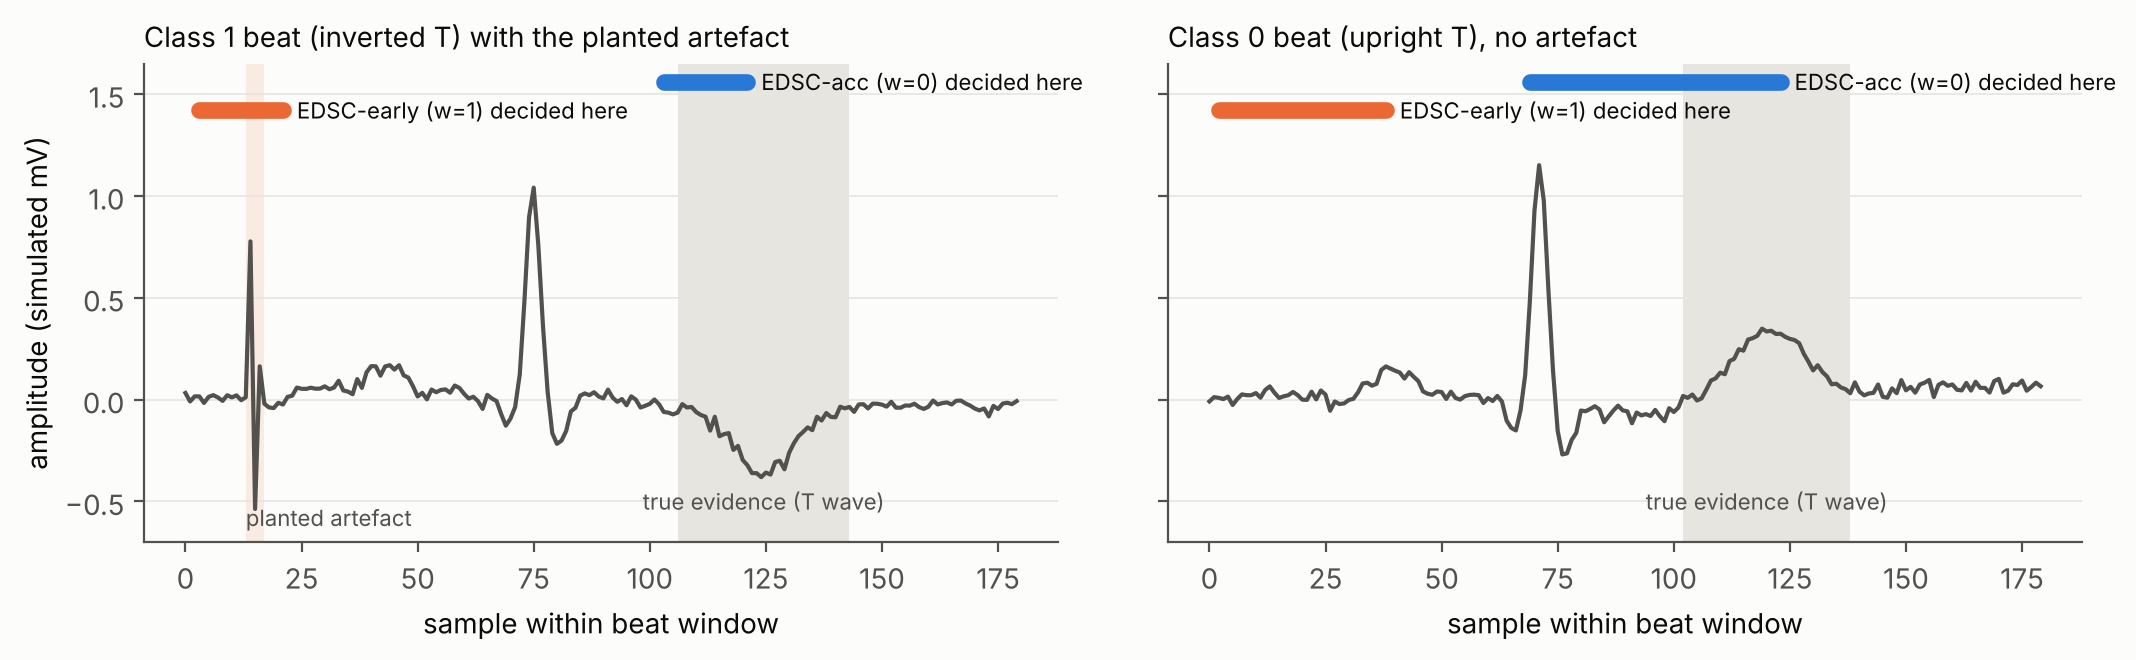

In [5]:
# Figure 1: where did each classifier look? (seed 0, two IID test beats)
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
rng = np.random.default_rng(1000)
tr = synecg_base(100, rng); Xtr_s, _, _ = synecg_with_artefact(tr, RHO_TRAIN); ytr_s = tr["y"]
te = synecg_base(200, rng); pool_s = build_pool(Xtr_s, ytr_s, rng)
m_early = fit(pool_s, ytr_s, METHODS["EDSC-early (w=1)"]); m_acc = fit(pool_s, ytr_s, METHODS["EDSC-acc (w=0)"])
Xte_s, present_s, art_s = synecg_with_artefact(te, 0.9)
_, _, _, ev_e = predict_first(m_early, Xte_s, 0); _, _, _, ev_a = predict_first(m_acc, Xte_s, 0)
i1 = int(np.where((te["y"] == 1) & present_s)[0][0]); i0 = int(np.where((te["y"] == 0) & ~present_s)[0][0])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, i, title in [(axes[0], i1, "Class 1 beat (inverted T) with the planted artefact"),
                     (axes[1], i0, "Class 0 beat (upright T), no artefact")]:
    x = Xte_s[i]
    ax.axvspan(*te["twave"][i], color=GRID, lw=0)
    ax.text(np.mean(te["twave"][i]), -0.5, "true evidence (T wave)", ha="center", va="center", color=INK2, fontsize=8)
    if present_s[i]:
        ax.axvspan(*art_s[i], color=C_ORANGE, alpha=0.12, lw=0)
        ax.text(art_s[i][0], -0.62, "planted artefact", color=INK2, fontsize=8)
    ax.plot(x, color=INK2, lw=1.5)
    for ev, col, yb, lab in [(ev_e, C_ORANGE, 1.42, "EDSC-early (w=1) decided here"),
                             (ev_a, C_BLUE, 1.56, "EDSC-acc (w=0) decided here")]:
        for (s0, s1) in ev[i]:
            ax.plot([s0, s1], [yb, yb], color=col, lw=6, solid_capstyle="round")
            ax.text(s1 + 3, yb, lab, color=INK, fontsize=8, va="center")
    ax.set_title(title, fontsize=10, color=INK, loc="left"); ax.set_xlabel("sample within beat window")
    ax.set_ylim(-0.7, 1.65); ax.grid(axis="y", color=GRID, lw=0.6)
axes[0].set_ylabel("amplitude (simulated mV)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_where_it_looked.png", dpi=200); plt.show()

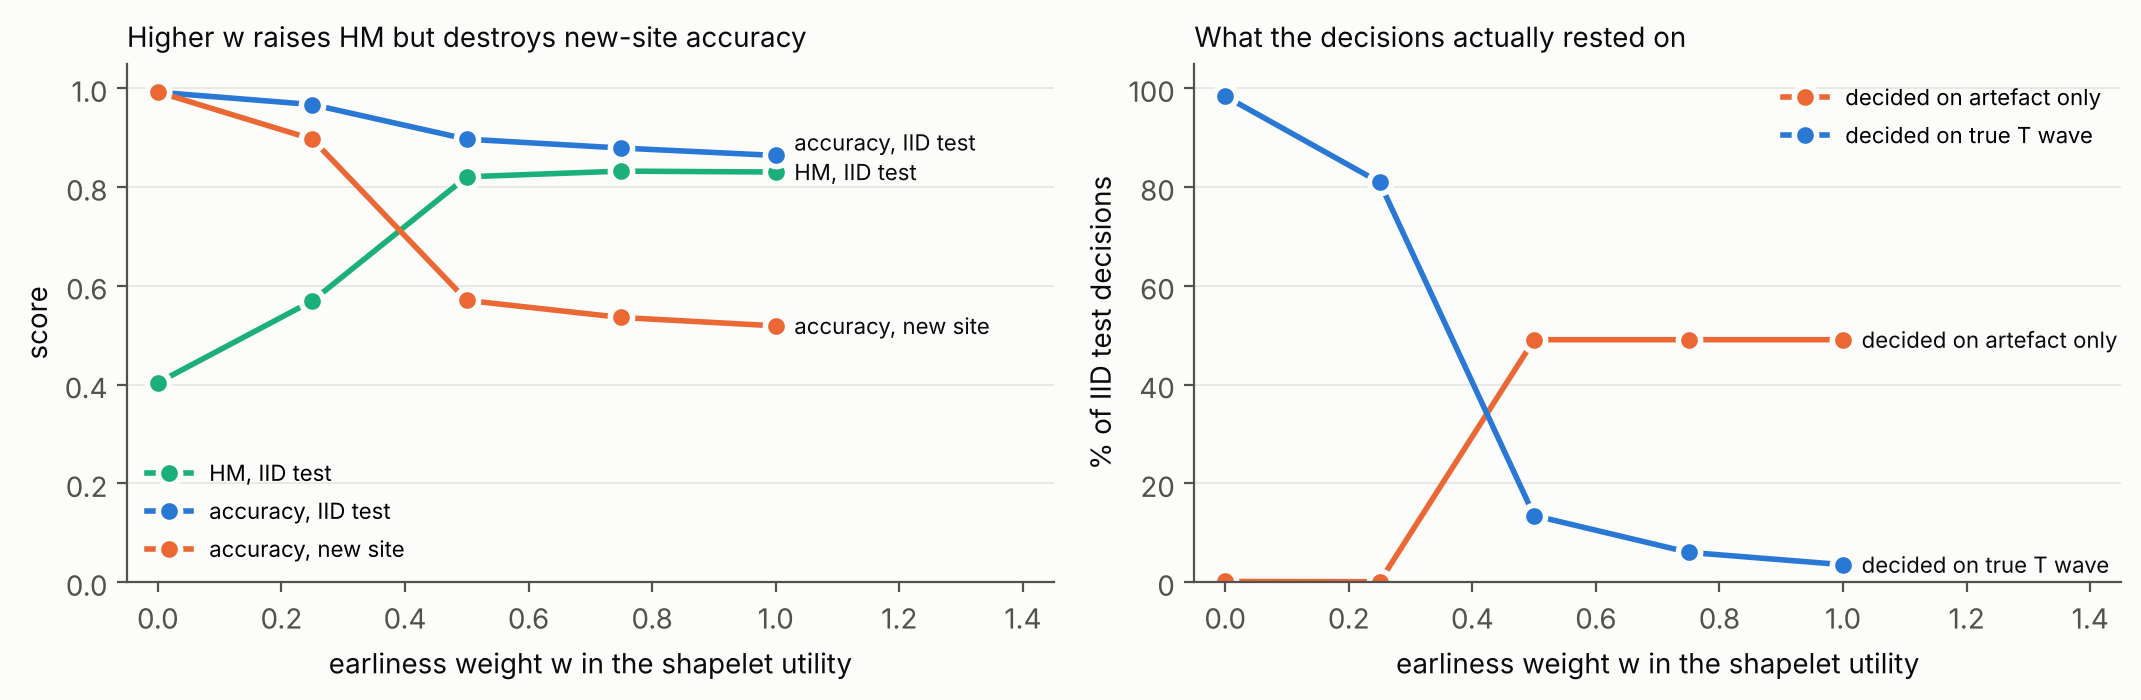

   w          condition   acc    hm  shortcut  faithful
0.00      IID (rho=0.9) 0.992 0.404     0.002     0.984
0.00 new site (rho=0.5) 0.992 0.404     0.002     0.984
0.00 reversed (rho=0.1) 0.994 0.403     0.000     0.986
0.25      IID (rho=0.9) 0.967 0.570     0.001     0.810
0.25 new site (rho=0.5) 0.897 0.556     0.001     0.806
0.25 reversed (rho=0.1) 0.837 0.537     0.000     0.814
0.50      IID (rho=0.9) 0.897 0.821     0.491     0.135
0.50 new site (rho=0.5) 0.570 0.650     0.494     0.130
0.50 reversed (rho=0.1) 0.222 0.336     0.498     0.126
0.75      IID (rho=0.9) 0.879 0.832     0.491     0.060
0.75 new site (rho=0.5) 0.536 0.638     0.494     0.062
0.75 reversed (rho=0.1) 0.167 0.274     0.498     0.057
1.00      IID (rho=0.9) 0.864 0.830     0.491     0.036
1.00 new site (rho=0.5) 0.519 0.629     0.494     0.034
1.00 reversed (rho=0.1) 0.156 0.259     0.498     0.030


In [6]:
# Figure 2: earliness weight w in the utility vs reliability (EDSC first-match rule), mean over 5 seeds
g = sweepA.groupby(["w", "condition"])[["acc", "hm", "shortcut", "faithful"]].mean().reset_index()
iidg = g[g.condition == "IID (rho=0.9)"]; newg = g[g.condition == "new site (rho=0.5)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
def spread(vals, gap):
    # nudge end-of-line label positions apart so they never collide
    order = np.argsort(vals); out = np.array(vals, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < gap: out[b] = out[a] + gap
    return out
series = [(iidg.hm.values, C_AQUA, "HM, IID test"), (iidg.acc.values, C_BLUE, "accuracy, IID test"),
          (newg.acc.values, C_ORANGE, "accuracy, new site")]
ly = spread([sv[0][-1] for sv in series], 0.06)
for (y, col, lab), yl in zip(series, ly):
    ax.plot(iidg.w.values, y, color=col, lw=2, marker="o", ms=8, mec="#fcfcfb", mew=2, label=lab)
    ax.text(1.03, yl, lab, color=INK, fontsize=8, va="center")
ax.set_xlabel("earliness weight w in the shapelet utility"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05)
ax.set_xlim(-0.05, 1.45); ax.grid(axis="y", color=GRID, lw=0.6); ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Higher w raises HM but destroys new-site accuracy", fontsize=10, loc="left", color=INK)
ax = axes[1]
for y, col, lab in [(100 * iidg.shortcut.values, C_ORANGE, "decided on artefact only"),
                    (100 * iidg.faithful.values, C_BLUE, "decided on true T wave")]:
    ax.plot(iidg.w.values, y, color=col, lw=2, marker="o", ms=8, mec="#fcfcfb", mew=2, label=lab)
    ax.text(1.03, y[-1], lab, color=INK, fontsize=8, va="center")
ax.set_xlabel("earliness weight w in the shapelet utility"); ax.set_ylabel("% of IID test decisions")
ax.set_ylim(0, 105); ax.set_xlim(-0.05, 1.45); ax.grid(axis="y", color=GRID, lw=0.6)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("What the decisions actually rested on", fontsize=10, loc="left", color=INK)
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_earliness_weight_sweep.png", dpi=200); plt.show()
print(g.round(3).to_string(index=False))

## 3. Experiment B — UCR datasets under realistic acquisition shifts

GunPoint and ItalyPowerDemand (default UCR splits, bundled with aeon, so this runs offline). Each shift is applied to
the clean test set with severities defined relative to the training data's standard deviation. The full-length
1-NN Euclidean classifier is a non-early reference.

In [7]:
dfB, pB = run_experiment_B()
CONDS = [cond_name(k, l) for k, l in SHIFTS if k != "clean"]
tabB = pd.concat([shift_table(dfB, pB, d, list(METHODS) + ["1NN-ED (full length)"], "clean", CONDS)
                  for d in ["GunPoint", "ItalyPowerDemand"]], ignore_index=True)
clean = dfB[dfB.condition == "clean"].groupby(["dataset", "method"])[["acc", "earliness", "hm", "fallback", "K"]].mean()
print("Clean test scores, mean over 5 seeds"); print(clean.round(3))
cols = ["dataset", "method", "condition", "acc_ref", "acc", "delta_pts", "ci_lo", "ci_hi", "sig_seeds",
        "earliness", "fallback", "silent_expl_change"]
print("\nAccuracy change under shift (points, 95% CI) and silent explanation change")
print(tabB[cols].round(3).to_string(index=False))

Clean test scores, mean over 5 seeds
                                         acc  earliness     hm  fallback     K
dataset          method                                                       
GunPoint         1NN-ED (full length)  0.913      1.000  0.000       NaN   NaN
                 Div-2 corroborated    0.860      0.746  0.388     0.277  12.8
                 Dup-2 corroborated    0.831      0.935  0.118     0.647  12.0
                 EDSC-acc (w=0)        0.831      0.414  0.687     0.015   6.6
                 EDSC-early (w=1)      0.871      0.250  0.806     0.003   6.0
ItalyPowerDemand 1NN-ED (full length)  0.955      1.000  0.000       NaN   NaN
                 Div-2 corroborated    0.747      0.440  0.639     0.041  18.6
                 Dup-2 corroborated    0.739      0.481  0.609     0.115  20.2
                 EDSC-acc (w=0)        0.745      0.610  0.506     0.021   6.2
                 EDSC-early (w=1)      0.675      0.205  0.730     0.005  10.8

Accuracy chang

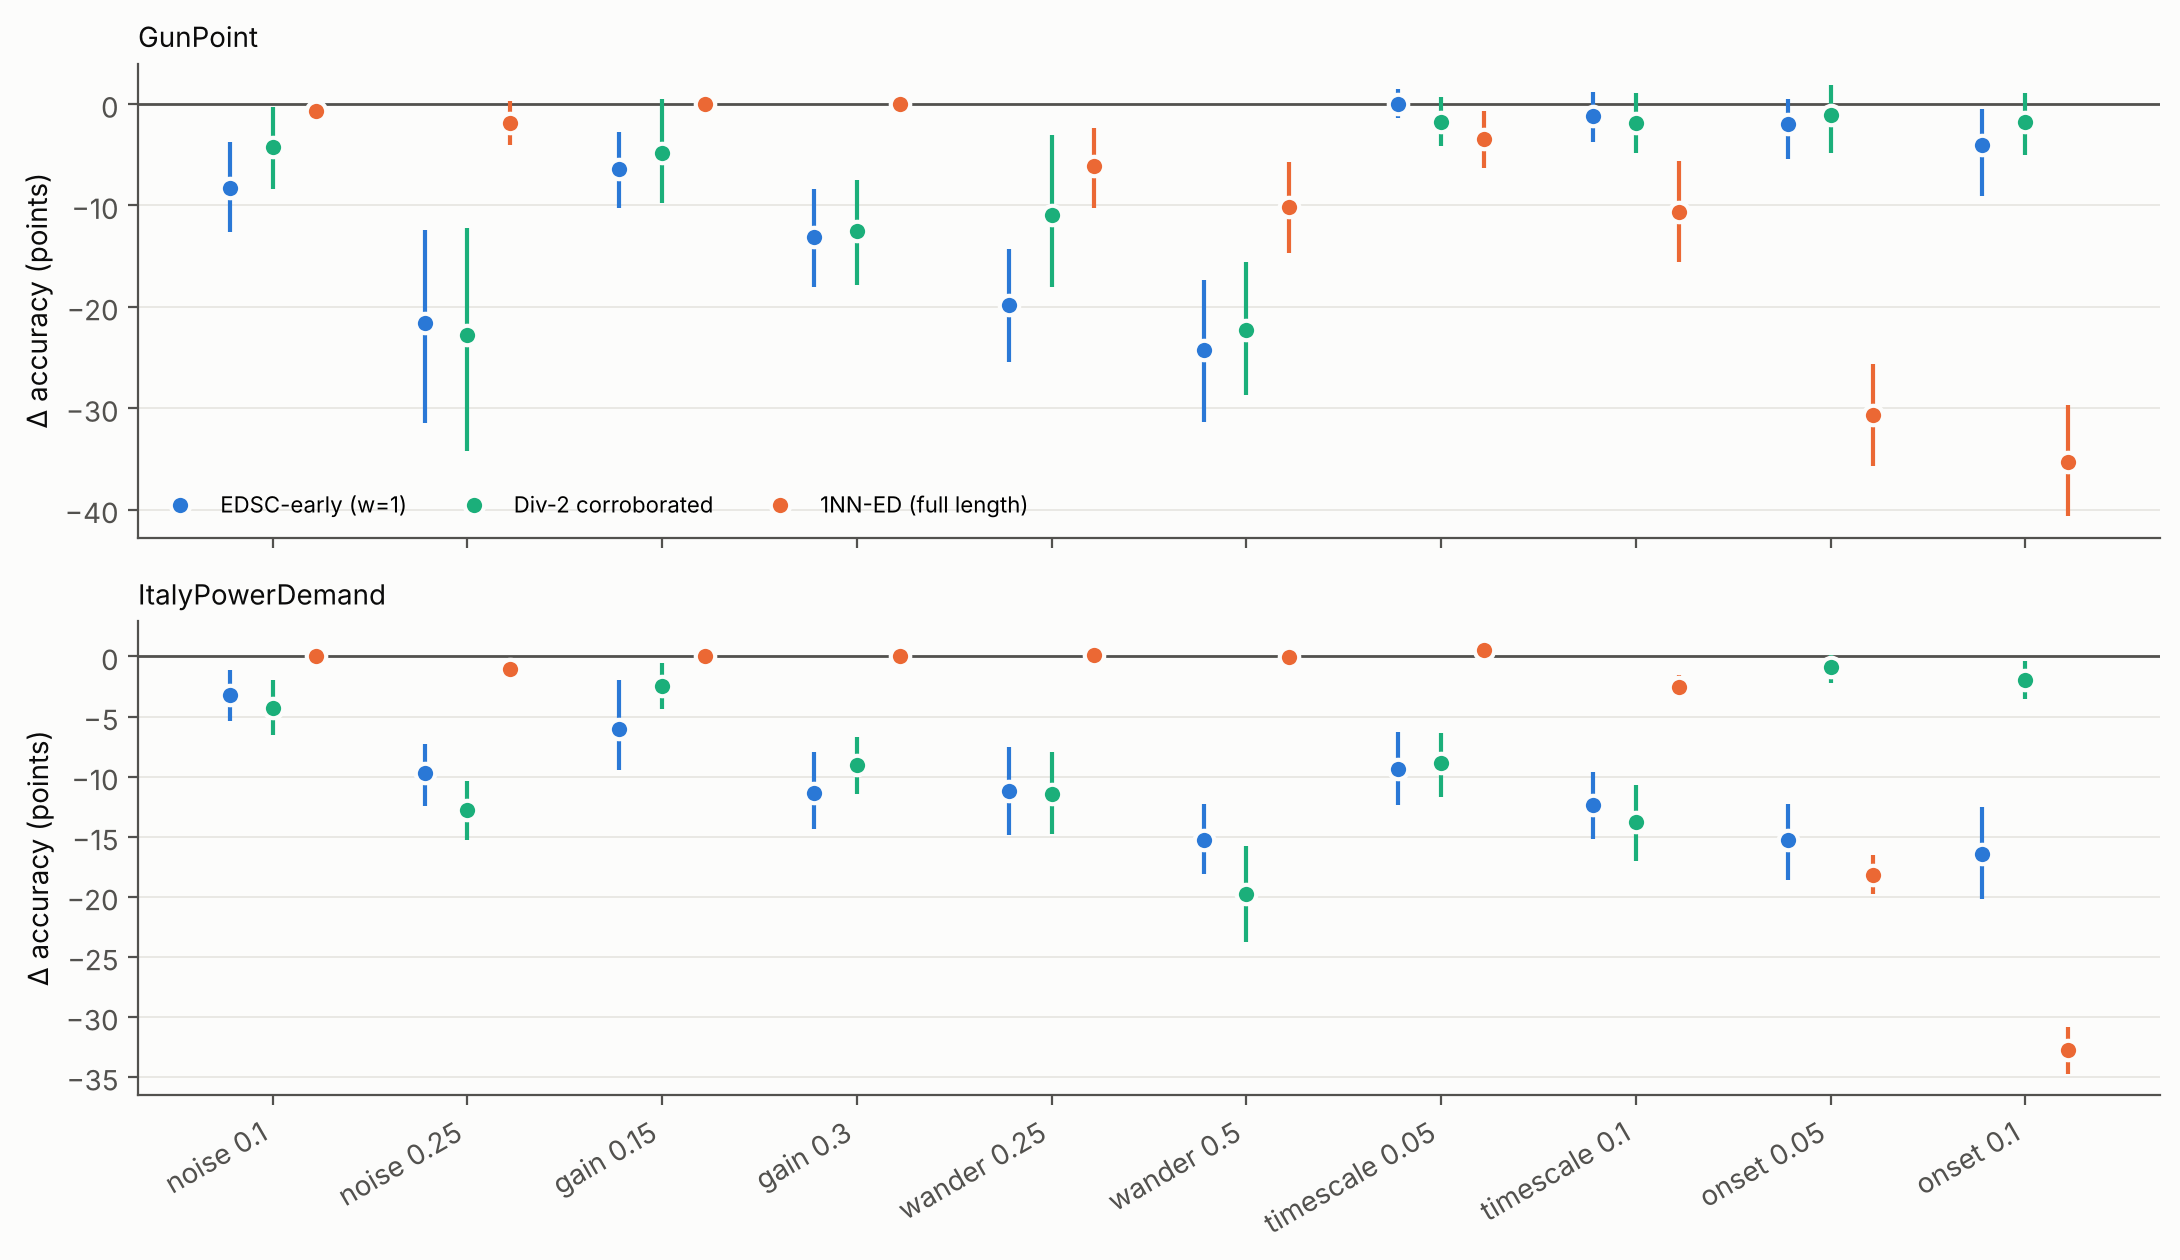

In [8]:
# Figure 3: accuracy change under each shift, with 95% CIs
show = [("EDSC-early (w=1)", C_BLUE), ("Div-2 corroborated", C_AQUA), ("1NN-ED (full length)", C_ORANGE)]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
xs = np.arange(len(CONDS))
for ax, d in zip(axes, ["GunPoint", "ItalyPowerDemand"]):
    ax.axhline(0, color=INK2, lw=1)
    for k, (m, col) in enumerate(show):
        sub = tabB[(tabB.dataset == d) & (tabB.method == m)].set_index("condition").loc[CONDS]
        off = (k - 1) * 0.22
        ax.errorbar(xs + off, sub.delta_pts, yerr=[sub.delta_pts - sub.ci_lo, sub.ci_hi - sub.delta_pts],
                    fmt="o", ms=7, color=col, ecolor=col, elinewidth=1.5, capsize=0, mec="#fcfcfb", mew=1.5, label=m)
    ax.set_ylabel("Δ accuracy (points)"); ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_title(d, fontsize=10, loc="left", color=INK)
axes[0].legend(frameon=False, fontsize=8, ncol=3, loc="lower left")
axes[1].set_xticks(xs); axes[1].set_xticklabels(CONDS, rotation=30, ha="right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_ucr_shift_profile.png", dpi=200); plt.show()

## 4. Headline numbers from *this* run

Only quote numbers printed by your own run.

In [9]:
def row(t, d, m, c):
    return t[(t.dataset == d) & (t.method == m) & (t.condition == c)].iloc[0]
iidm = dfA[dfA.condition == "IID (rho=0.9)"].groupby("method").mean(numeric_only=True)
a_new = row(tabA, "SynECG", "EDSC-early (w=1)", "new site (rho=0.5)")
a_new0 = row(tabA, "SynECG", "EDSC-acc (w=0)", "new site (rho=0.5)")
a_div = row(tabA, "SynECG", "Div-2 corroborated", "new site (rho=0.5)")
g_wan = row(tabB, "GunPoint", "EDSC-early (w=1)", "wander 0.5")
g_gain = row(tabB, "GunPoint", "EDSC-early (w=1)", "gain 0.15")
g_on_nn = row(tabB, "GunPoint", "1NN-ED (full length)", "onset 0.1")
g_on_sh = row(tabB, "GunPoint", "EDSC-early (w=1)", "onset 0.1")
H = {
    "synecg_hm_early": iidm.loc["EDSC-early (w=1)", "hm"], "synecg_hm_acc": iidm.loc["EDSC-acc (w=0)", "hm"],
    "synecg_acc_iid_early": iidm.loc["EDSC-early (w=1)", "acc"], "synecg_earliness_early": iidm.loc["EDSC-early (w=1)", "earliness"],
    "synecg_shortcut_early_pct": 100 * iidm.loc["EDSC-early (w=1)", "shortcut"],
    "synecg_faithful_early_pct": 100 * iidm.loc["EDSC-early (w=1)", "faithful"],
    "synecg_faithful_acc_pct": 100 * iidm.loc["EDSC-acc (w=0)", "faithful"],
    "synecg_newsite_acc_early": a_new.acc, "synecg_newsite_delta": a_new.delta_pts,
    "synecg_newsite_ci": [a_new.ci_lo, a_new.ci_hi], "synecg_newsite_sig_seeds": int(a_new.sig_seeds),
    "synecg_newsite_delta_acc_variant": a_new0.delta_pts, "synecg_acc_iid_acc": iidm.loc["EDSC-acc (w=0)", "acc"],
    "synecg_div2_newsite_delta": a_div.delta_pts, "synecg_div2_newsite_ci": [a_div.ci_lo, a_div.ci_hi],
    "synecg_div2_earliness": iidm.loc["Div-2 corroborated", "earliness"],
    "gunpoint_clean_acc_early": g_wan.acc_ref, "gunpoint_wander_delta": g_wan.delta_pts,
    "gunpoint_wander_ci": [g_wan.ci_lo, g_wan.ci_hi], "gunpoint_wander_sig_seeds": int(g_wan.sig_seeds),
    "gunpoint_gain015_delta": g_gain.delta_pts, "gunpoint_gain015_silent_pct": 100 * g_gain.silent_expl_change,
    "gunpoint_onset01_delta_1nn": g_on_nn.delta_pts, "gunpoint_onset01_delta_early": g_on_sh.delta_pts,
}
H = {k: (np.round(v, 3).tolist() if isinstance(v, (list, np.ndarray)) else (int(v) if k.endswith("sig_seeds") else round(float(v), 3))) for k, v in H.items()}
json.dump(H, open(f"{OUT}/headline.json", "w"), indent=2)
print(f"""SynECG (simulated, planted artefact): earliness-weighted selection (w=1) scored the best HM in-distribution
({H['synecg_hm_early']:.2f} vs {H['synecg_hm_acc']:.2f} for w=0; IID accuracy {H['synecg_acc_iid_early']:.3f}, earliness {H['synecg_earliness_early']:.2f}),
yet {H['synecg_shortcut_early_pct']:.1f}% of its decisions rested only on the artefact and {H['synecg_faithful_early_pct']:.1f}% on the true T wave
(w=0: {H['synecg_faithful_acc_pct']:.1f}%). At a new site its accuracy fell to {H['synecg_newsite_acc_early']:.3f}
(change {H['synecg_newsite_delta']:.1f} points, 95% CI [{H['synecg_newsite_ci'][0]:.1f}, {H['synecg_newsite_ci'][1]:.1f}], significant in {H['synecg_newsite_sig_seeds']}/5 seeds);
w=0 changed by {H['synecg_newsite_delta_acc_variant']:+.1f}. Diversity-constrained corroboration: {H['synecg_div2_newsite_delta']:.1f} points
[{H['synecg_div2_newsite_ci'][0]:.1f}, {H['synecg_div2_newsite_ci'][1]:.1f}] at earliness {H['synecg_div2_earliness']:.2f}.
GunPoint (w=1): baseline wander 0.5 changed accuracy by {H['gunpoint_wander_delta']:.1f} points [{H['gunpoint_wander_ci'][0]:.1f}, {H['gunpoint_wander_ci'][1]:.1f}]
({H['gunpoint_wander_sig_seeds']}/5 seeds); under ±15% gain accuracy changed by {H['gunpoint_gain015_delta']:.1f} points while
{H['gunpoint_gain015_silent_pct']:.1f}% of series stayed correct but switched to a different triggering shapelet.
10% onset misalignment: full-length 1-NN {H['gunpoint_onset01_delta_1nn']:.1f} points vs shapelets {H['gunpoint_onset01_delta_early']:.1f}.""")

SynECG (simulated, planted artefact): earliness-weighted selection (w=1) scored the best HM in-distribution
(0.83 vs 0.40 for w=0; IID accuracy 0.864, earliness 0.20),
yet 49.1% of its decisions rested only on the artefact and 3.5% on the true T wave
(w=0: 98.4%). At a new site its accuracy fell to 0.519
(change -34.5 points, 95% CI [-38.3, -30.4], significant in 5/5 seeds);
w=0 changed by +0.1. Diversity-constrained corroboration: -7.7 points
[-13.1, -3.0] at earliness 0.70.
GunPoint (w=1): baseline wander 0.5 changed accuracy by -24.3 points [-31.3, -17.3]
(5/5 seeds); under ±15% gain accuracy changed by -6.4 points while
16.5% of series stayed correct but switched to a different triggering shapelet.
10% onset misalignment: full-length 1-NN -35.3 points vs shapelets -4.0.


## 5. Optional — real ECG check (needs internet; runs in Colab)

Repeats Experiment B on two UCR ECG datasets (ECG200, TwoLeadECG), downloaded through aeon; this needs internet access.
If the download fails the cell says so and nothing else is affected.

In [10]:
RUN_REAL_ECG = True
if RUN_REAL_ECG:
    try:
        dfE, pE = run_experiment_B(datasets=("ECG200", "TwoLeadECG"))
        tabE = pd.concat([shift_table(dfE, pE, d, list(METHODS) + ["1NN-ED (full length)"], "clean", CONDS)
                          for d in ["ECG200", "TwoLeadECG"]], ignore_index=True)
        print(dfE[dfE.condition == "clean"].groupby(["dataset", "method"])[["acc", "earliness", "hm", "fallback"]].mean().round(3))
        print(tabE[cols].round(3).to_string(index=False))
        tabE.to_csv(f"{OUT}/table_real_ecg_shifts.csv", index=False)
    except Exception as e:
        print("Real-ECG check skipped (download unavailable here):", type(e).__name__, str(e)[:160])

Real-ECG check skipped (download unavailable here): ValueError Could not download files for ECG200 from Zenodo record 11186675: ValueError: Failed to retrieve Zenodo metadata for record 11186675: <urlopen error Tunnel conne


## 6. Save everything

In [11]:
dfA.to_csv(f"{OUT}/runs_synecg.csv", index=False); sweepA.to_csv(f"{OUT}/sweep_synecg.csv", index=False)
dfB.to_csv(f"{OUT}/runs_ucr.csv", index=False); tabA.to_csv(f"{OUT}/table_synecg_shift.csv", index=False)
tabB.to_csv(f"{OUT}/table_ucr_shifts.csv", index=False)
print("saved to", OUT, sorted(os.listdir(OUT)))
print(f"total runtime {time.time() - T_START:.0f} s")

saved to secr_outputs ['fig1_where_it_looked.png', 'fig2_earliness_weight_sweep.png', 'fig3_ucr_shift_profile.png', 'headline.json', 'runs_synecg.csv', 'runs_ucr.csv', 'sweep_synecg.csv', 'table_synecg_shift.csv', 'table_ucr_shifts.csv']
total runtime 17 s


## 7. What this pilot does and does not show

* It shows that a standard single-number early-classification score (HM) can **prefer a shortcut model**: rewarding
  earliness makes an early spurious pattern more attractive than late true evidence, and only an evidence audit
  (which needs ground truth about *where* evidence lies) or a shifted test reveals it.
* It shows that thresholded shapelet matching degrades under acquisition shifts in ways that differ from a full-length
  classifier (shapelets tolerate onset misalignment; 1-NN tolerates gain), and that explanations can change even when
  the label does not.
* It does **not** show anything about clinical ECG performance, about any specific published method, or about
  multivariate series. Natural next steps: real multi-site ECG (PTB-XL, MIT-BIH), comparison with IEDSC-style
  trend-aware similarity, causal (prefix-only) normalisation, and calibrated abstention instead of fixed thresholds.

**Related work.** Ye & Keogh (KDD 2009, shapelets); Xing, Pei, Yu & Wang (SDM 2011, EDSC); Li, Yan & Wu (ESWA 2019,
key-point shapelets); Yan, Li, Wu, Wang & Yu (World Wide Web 2020, diverse shapelets / IEDSC); Li & Yan (KSEM 2020,
random selection); Schäfer & Leser (DMKD 2020, TEASER); Wu, Der & Keogh (IEEE TKDE 2021, when early classification is
meaningful); Geirhos et al. (Nature Machine Intelligence 2020, shortcut learning).